# SmartRoad Preditiva — esta ocorrência vai demorar mais de 30 dias?

**Global Solution 2026.2 · CitizenTech · Inteligência Artificial & Machine Learning**
**CitizenTech:** SmartRoad (app em que o morador de São Paulo registra e acompanha buracos, bueiros e calçadas danificadas)

| Etapa do percurso | Onde está neste notebook |
| --- | --- |
| 01 · Problema e dados reais | Seções 1 e 2 |
| 02 · Modelo e preparação (inclui a série temporal) | Seções 3 e 4 |
| 03 · Treino e avaliação | Seção 5 |
| 04 · Resultados e conclusão | Seções 6 e 7 |

## 1. O problema da CitizenTech virou uma pergunta de Machine Learning

No SmartRoad o cidadão registra um problema da rua e acompanha o andamento (Recebida → Em andamento → Concluída). O que o app **não** consegue dizer hoje é a primeira coisa que o morador quer saber: *"isso vai demorar?"*. O indicador de impacto da nossa Ficha é justamente o tempo entre o registro e a conclusão.

**Pergunta de ML:** no momento em que uma ocorrência de zeladoria é registrada, dá para prever se ela vai **demorar mais de 30 dias para ser finalizada**?

- **Tipo de problema:** classificação binária supervisionada.
- **Alvo (`demora`):** 1 = a solicitação não foi finalizada em até 30 dias; 0 = foi finalizada em até 30 dias.
- **Entradas:** só o que o app sabe na hora do registro (tipo de serviço, canal, região, coordenadas, dia da semana) mais o **histórico recente do serviço e da região** (a parte de série temporal: fila de pedidos em aberto, ritmo de finalização e taxa de demora dos últimos meses).
- **Dados:** solicitações reais feitas à Prefeitura de São Paulo pelo SP156 (nada simulado).

In [1]:
# Bibliotecas (versões em ml/requirements.txt)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from xgboost import XGBClassifier

SEMENTE = 42  # mesma semente em tudo, para o resultado se repetir

# Padrão visual dos gráficos: azul = treino, laranja = teste/validação, grade discreta.
AZUL, LARANJA, CINZA, TEXTO = "#2a78d6", "#eb6834", "#8a8983", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TEXTO, "xtick.color": TEXTO, "ytick.color": TEXTO, "font.size": 10,
    "lines.linewidth": 2, "legend.frameon": False,
})
PASTA_FIGURAS = Path("figuras")
PASTA_FIGURAS.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 80)

## 2. Dados reais e públicos: SP156

| | |
| --- | --- |
| **Fonte** | Portal de Dados Abertos da Prefeitura de São Paulo — conjunto "Dados do SP156 - Solicitações" |
| **Link** | https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156 |
| **Período** | solicitações abertas de **01/07/2024 a 30/06/2026**, 2 anos corridos (8 arquivos trimestrais: do 3º trimestre de 2024 ao 2º de 2026) |
| **Situação dos dados** | os arquivos de 2025 e 2026 foram republicados pela Prefeitura em 10/08/2026; o status e a data de finalização valem até essa extração (a finalização mais recente é de 10/08/2026) |
| **Licença** | Creative Commons CC0 (domínio público) |
| **Baixado em** | 14/11/2026 |

Os oito arquivos originais somam cerca de 930 MB e 4,7 milhões de solicitações de todos os assuntos (trânsito, lixo, saúde...). O arquivo do 2º trimestre de 2024 não traz a coluna "Serviço", por isso a série começa em 01/07/2024: assim ela fica contínua, sem buraco no meio. O script `dados/preparar_dados.py` baixa esses arquivos e guarda só o que interessa ao SmartRoad: os **9 serviços** que correspondem aos tipos de ocorrência do app. Ele só filtra linhas e colunas; nenhum valor é alterado. Detalhes em `dados/README.md`.

| Tipo no SmartRoad | Serviços do SP156 |
| --- | --- |
| Buraco | Tapa-buraco · Tapa-buraco em faixa exclusiva ou corredor de ônibus |
| Bueiro quebrado | Limpeza de bueiros, boca de lobo e poços de visita · Drenagem: bueiros e bocas de lobo · Reformar galerias de águas de chuva |
| Calçada danificada | Calçada pública: manutenção · Calçada particular danificada ou inexistente · Obstáculo na calçada (acessibilidade) · Guias, sarjetas e sarjetões: manutenção |
| Iluminação | *não existe serviço de iluminação pública nos arquivos do SP156 deste período, então fica fora do modelo* |

In [2]:
# Leitura do recorte. Fora do repositório (ex.: Google Colab), lê o mesmo arquivo direto do GitHub.
ARQUIVO = Path("dados/sp156_zeladoria_jul2024_jun2026.csv.gz")
URL = "https://raw.githubusercontent.com/MAJE-Dev/SmartRoad-Preditiva/main/ml/dados/sp156_zeladoria_jul2024_jun2026.csv.gz"

bruto = pd.read_csv(ARQUIVO if ARQUIVO.exists() else URL, dtype=str)

print(f"Linhas: {len(bruto):,} | Colunas: {bruto.shape[1]}")
bruto.head()

Linhas: 387,605 | Colunas: 11


,tipo_smartroad,data_abertura,data_finalizacao,canal,servico,status,orgao,latitude,longitude,subprefeitura,distrito
0,Buraco,01/07/2024,06/08/2024,MOBILE,Tapa-buraco,Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.5710416,-46.4043707,CIDADE TIRADENTES,CIDADE TIRADENTES
1,Buraco,01/07/2024,06/08/2024,PORTAL,Tapa-buraco,Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.5864869,-46.6245303,VILA MARIANA,VILA MARIANA
2,Buraco,01/07/2024,05/08/2024,PORTAL,Tapa-buraco,Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.5664406,-46.6686668,PINHEIROS,JARDIM PAULISTA
3,Calçada,01/07/2024,14/11/2024,CRM,"Guias, sarjetas e sarjetões - solicitar manutenção",Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.4569312,-46.7013344,FREGUESIA-BRASILANDIA,BRASILANDIA
4,Bueiro,01/07/2024,14/11/2024,CRM,Reformar galerias de águas de chuvas (pluviais),Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.4653733,-46.6969833,FREGUESIA-BRASILANDIA,BRASILANDIA


In [3]:
# Auditoria inicial: valores vazios e categorias de cada coluna
auditoria = pd.DataFrame({
    "vazios": bruto.isna().sum(),
    "% vazios": (bruto.isna().mean() * 100).round(1),
    "valores distintos": bruto.nunique(),
})
display(auditoria)

print("Status das solicitações na data da extração:")
display(bruto["status"].value_counts().to_frame("solicitações"))

,vazios,% vazios,valores distintos
tipo_smartroad,0,0.0,3
data_abertura,0,0.0,730
data_finalizacao,62871,16.2,768
canal,0,0.0,5
servico,0,0.0,9
status,0,0.0,4
orgao,0,0.0,11
latitude,2,0.0,240053
longitude,2,0.0,235855
subprefeitura,611,0.2,39


Status das solicitações na data da extração:


,solicitações
status,
Finalizada,323599
Aberto,61649
Cancelada,2241
Em Andamento,116


**O que a auditoria mostra**

- A única coluna com muitos vazios é `data_finalizacao`. Isso é esperado: são as solicitações que ainda estavam abertas na extração. Essa informação vira o nosso alvo, não um defeito a corrigir.
- `status` e `data_finalizacao` são a "resposta" do problema. `orgao` é o órgão responsável **na data da extração** e, segundo o dicionário do SP156, pode mudar depois da abertura. Nenhuma dessas três colunas pode entrar como entrada do modelo para o **próprio pedido**: seria vazamento de informação do futuro. (O que a Prefeitura já tinha finalizado **antes** do dia do registro pode, e é assim que a série temporal da Seção 3.4 usa essas datas.)

## 3. Preparação dos dados

### 3.1 Limpeza

Cada passo abaixo remove ou corrige um problema específico, e a tabela no final mostra quantas linhas saíram em cada um.

In [4]:
dados = bruto.copy()
funil = {"Recorte original": len(dados)}

# 1) Tipos: datas (dd/mm/aaaa) e coordenadas viram data e número
dados["data_abertura"] = pd.to_datetime(dados["data_abertura"], format="%d/%m/%Y")
dados["data_finalizacao"] = pd.to_datetime(dados["data_finalizacao"], format="%d/%m/%Y")
dados["latitude"] = pd.to_numeric(dados["latitude"])
dados["longitude"] = pd.to_numeric(dados["longitude"])

# 2) Canceladas: quem cancelou foi o cidadão, então não dizem nada sobre o tempo da Prefeitura
dados = dados[dados["status"] != "Cancelada"]
funil["Sem as canceladas pelo cidadão"] = len(dados)

# 3) "Finalizada" sem data de finalização: não dá para calcular o tempo
dados = dados[~((dados["status"] == "Finalizada") & dados["data_finalizacao"].isna())]
funil["Sem finalizadas sem data"] = len(dados)

# 4) Canal "RESOLUCAO": só 20 linhas, e não está entre os canais de atendimento descritos no dicionário
dados = dados[dados["canal"] != "RESOLUCAO"]
funil["Sem o canal RESOLUCAO"] = len(dados)

# 5) Coordenadas fora do município de São Paulo (erro de cadastro, como latitude 0)
dentro_de_sp = dados["latitude"].between(-24.1, -23.3) & dados["longitude"].between(-46.9, -46.3)
dados = dados[dentro_de_sp]
funil["Com coordenadas dentro de São Paulo"] = len(dados)

# 6) Subprefeitura: duas mudaram de nome no meio do período; valores que não são região viram uma categoria só
dados["subprefeitura"] = dados["subprefeitura"].replace({
    "CASA VERDE-LIMAO-CACHOEIRINHA": "CASA VERDE-CACHOEIRINHA",
    "PERUS-ANHANGUERA": "PERUS",
})
NAO_E_REGIAO = ["Superintendencia das Usinas de Asfalto", "Prefeitura Regional nao encontrada",
                "Departamento de Aguas e Energia Eletrica", "Departamento de Estradas de Rodagem", "Secretaria Municipal do Verde e do Meio Ambiente"]
dados["subprefeitura"] = dados["subprefeitura"].replace(NAO_E_REGIAO, "NAO IDENTIFICADA").fillna("NAO IDENTIFICADA")

dados = dados.sort_values("data_abertura").reset_index(drop=True)

funil = pd.Series(funil, name="linhas").to_frame()
funil["removidas no passo"] = -funil["linhas"].diff().fillna(0).astype(int)
display(funil)

# Conferências: 32 subprefeituras de São Paulo + "NAO IDENTIFICADA", nenhuma data invertida
assert dados["subprefeitura"].nunique() == 33
assert (dados["data_finalizacao"].dropna() >= dados.loc[dados["data_finalizacao"].notna(), "data_abertura"]).all()
print(f"Ficaram {len(dados):,} solicitações ({len(dados) / len(bruto):.1%} do recorte).")

,linhas,removidas no passo
Recorte original,387605,0
Sem as canceladas pelo cidadão,385364,2241
Sem finalizadas sem data,384258,1106
Sem o canal RESOLUCAO,384237,21
Com coordenadas dentro de São Paulo,384139,98


Ficaram 384,139 solicitações (99.1% do recorte).


### 3.2 Construção do alvo

`dias_ate_finalizar` é a diferença entre a data de finalização e a de abertura. O alvo `demora` vale 1 quando a solicitação **não** foi finalizada em até 30 dias, o que inclui as que continuavam abertas na extração.

**Por que 30 dias?** A última solicitação do recorte foi aberta em 30/06/2026 e os arquivos trazem finalizações até 10/08/2026. Ou seja, toda solicitação foi observada por pelo menos 30 dias, e o alvo é conhecido para 100% das linhas. Se o alvo fosse "quantos dias demorou", teríamos que jogar fora as solicitações ainda abertas, que são justamente as mais demoradas, e o modelo aprenderia uma cidade mais rápida do que a real.

In [5]:
dados["dias_ate_finalizar"] = (dados["data_finalizacao"] - dados["data_abertura"]).dt.days
dados["demora"] = (~(dados["dias_ate_finalizar"] <= 30)).astype(int)  # ainda aberta (vazio) também conta como demora

# Toda solicitação teve pelo menos 30 dias para ser finalizada antes da extração?
ultima_abertura = dados["data_abertura"].max()
ultima_finalizacao = dados["data_finalizacao"].max()
print(f"Última abertura: {ultima_abertura:%d/%m/%Y} | última finalização registrada: {ultima_finalizacao:%d/%m/%Y}")
assert (ultima_finalizacao - ultima_abertura).days >= 30

resumo_alvo = dados["demora"].map({0: "0 · finalizada em até 30 dias", 1: "1 · demora mais de 30 dias"}).value_counts().to_frame("solicitações")
resumo_alvo["%"] = (resumo_alvo["solicitações"] / len(dados) * 100).round(1)
display(resumo_alvo)
print(f"Entre as finalizadas, metade fecha em até {dados['dias_ate_finalizar'].median():.0f} dias.")

Última abertura: 30/06/2026 | última finalização registrada: 10/08/2026


,solicitações,%
demora,,
0 · finalizada em até 30 dias,249395,64.9
1 · demora mais de 30 dias,134744,35.1


Entre as finalizadas, metade fecha em até 8 dias.


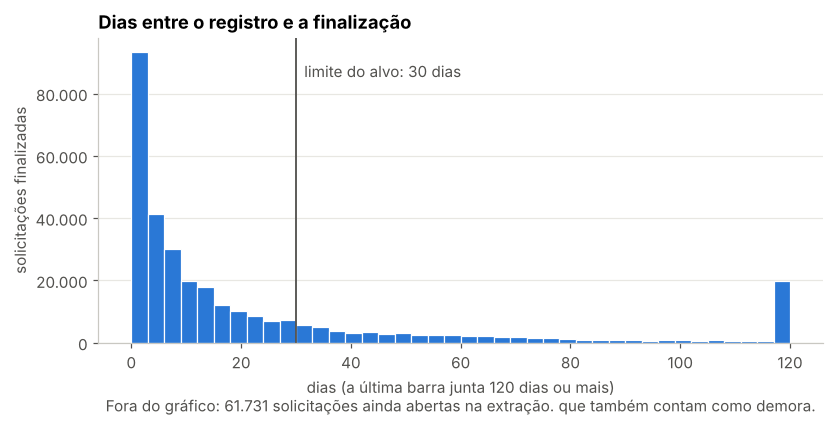

In [6]:
# Como o tempo até a finalização se distribui (só as finalizadas têm tempo conhecido)
finalizadas = dados["dias_ate_finalizar"].dropna()
abertas = dados["dias_ate_finalizar"].isna().sum()

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.hist(finalizadas.clip(upper=120), bins=range(0, 123, 3), color=AZUL, edgecolor="white", linewidth=0.8)
ax.axvline(30, color=TEXTO, linewidth=1.2)
ax.text(31.5, ax.get_ylim()[1] * 0.92, "limite do alvo: 30 dias", color=TEXTO, va="top")
ax.set_title("Dias entre o registro e a finalização")
ax.set_xlabel("dias (a última barra junta 120 dias ou mais)\n"
              + f"Fora do gráfico: {abertas:,} solicitações ainda abertas na extração, que também contam como demora.".replace(",", "."))
ax.set_ylabel("solicitações finalizadas")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
ax.grid(axis="x", visible=False)
fig.savefig(PASTA_FIGURAS / "01_dias_ate_finalizar.png")
plt.show()

### 3.3 O que os dados já contam antes do modelo

Antes de treinar, olhamos como a taxa de demora muda conforme o serviço e conforme o mês de abertura. Isso ajuda a escolher as entradas e, principalmente, a forma de dividir treino e teste.

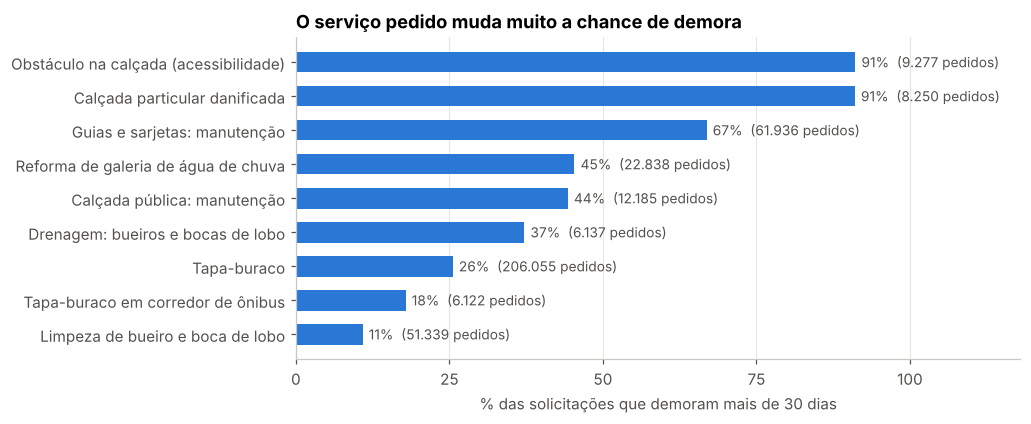

In [7]:
# Nomes curtos para os gráficos (os nomes oficiais do SP156 são longos)
NOME_CURTO = {
    "Tapa-buraco": "Tapa-buraco",
    "Tapa-buraco em faixa exclusiva ou corredor de ônibus": "Tapa-buraco em corredor de ônibus",
    "Solicitar limpeza de bueiros, boca de lobo e poços de visita": "Limpeza de bueiro e boca de lobo",
    "Drenagem de água da chuva - Bueiros e bocas de lobo": "Drenagem: bueiros e bocas de lobo",
    "Reformar galerias de águas de chuvas (pluviais)": "Reforma de galeria de água de chuva",
    "Calçada pública - solicitar manutenção": "Calçada pública: manutenção",
    "Calçada particular - denunciar calçada danificada ou inexistente": "Calçada particular danificada",
    "Acessibilidade - solicitar avaliação de obstáculo na calçada": "Obstáculo na calçada (acessibilidade)",
    "Guias, sarjetas e sarjetões - solicitar manutenção": "Guias e sarjetas: manutenção",
}

por_servico = dados.groupby("servico")["demora"].agg(taxa="mean", solicitacoes="size").sort_values("taxa")
por_servico.index = por_servico.index.map(NOME_CURTO)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
barras = ax.barh(por_servico.index, por_servico["taxa"] * 100, color=AZUL, height=0.6)
for barra, (taxa, n) in zip(barras, por_servico.itertuples(index=False)):
    ax.text(barra.get_width() + 1, barra.get_y() + barra.get_height() / 2,
            f"{taxa:.0%}  ({n:,} pedidos)".replace(",", "."), va="center", color=TEXTO, fontsize=9)
ax.set_xlim(0, 118)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_title("O serviço pedido muda muito a chance de demora")
ax.set_xlabel("% das solicitações que demoram mais de 30 dias")
ax.grid(axis="y", visible=False)
fig.savefig(PASTA_FIGURAS / "02_demora_por_servico.png")
plt.show()

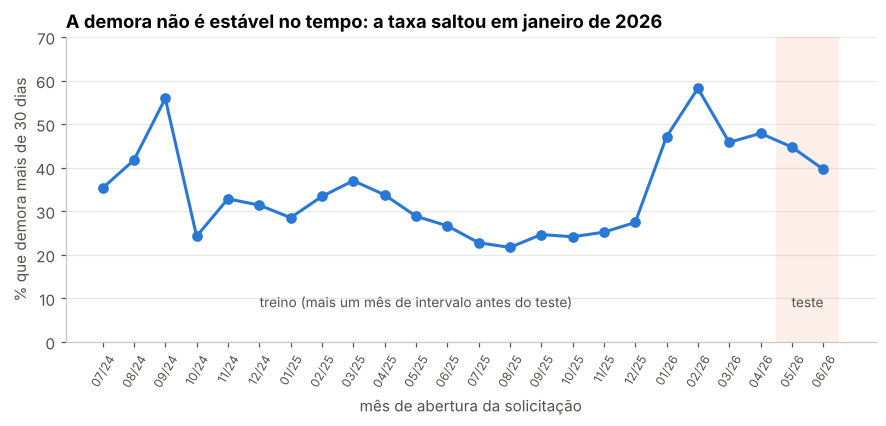

In [8]:
# Taxa de demora por mês de abertura
por_mes = dados.groupby(dados["data_abertura"].dt.to_period("M"))["demora"].mean() * 100
rotulos = [f"{p.month:02d}/{str(p.year)[2:]}" for p in por_mes.index]

fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(rotulos, por_mes.values, color=AZUL, marker="o", markersize=6)
ax.axvspan(21.5, 23.5, color=LARANJA, alpha=0.10, linewidth=0)
ax.text(22.5, 8, "teste", ha="center", color=TEXTO, fontsize=9)
ax.text(10, 8, "treino (mais um mês de intervalo antes do teste)", ha="center", color=TEXTO, fontsize=9)
ax.tick_params(axis="x", labelrotation=60, labelsize=8)
ax.set_ylim(0, 70)
ax.set_title("A demora não é estável no tempo: a taxa saltou em janeiro de 2026")
ax.set_xlabel("mês de abertura da solicitação")
ax.set_ylabel("% que demora mais de 30 dias")
ax.grid(axis="x", visible=False)
fig.savefig(PASTA_FIGURAS / "03_demora_por_mes.png")
plt.show()

In [9]:
# E a região? As 3 subprefeituras com menor e as 3 com maior taxa de demora
por_regiao = dados[dados["subprefeitura"] != "NAO IDENTIFICADA"].groupby("subprefeitura")["demora"].agg(
    taxa_de_demora="mean", solicitacoes="size").sort_values("taxa_de_demora")
por_regiao["taxa_de_demora"] = (por_regiao["taxa_de_demora"] * 100).round(1)
pd.concat([por_regiao.head(3), por_regiao.tail(3)])

,taxa_de_demora,solicitacoes
subprefeitura,,
JABAQUARA,19.0,5617
VILA PRUDENTE,22.0,7584
GUAIANASES,22.3,6524
ITAIM PAULISTA,45.2,15224
PIRITUBA-JARAGUA,46.3,18602
SE,47.7,15635


**Leitura dos gráficos**

- O **serviço** é o que mais separa os casos: limpeza de bueiro quase sempre fecha em 30 dias; denúncia de calçada particular e obstáculo na calçada quase nunca.
- A taxa de demora **é uma série temporal, e ela muda de regime**: ficou entre 22% e 37% quase todo o período, teve um pico em set/2024 (56%) e saltou para 40% a 58% a partir de jan/2026. Isso não é ruído: é a fila da Prefeitura crescendo ou esvaziando. Por isso o modelo precisa **enxergar o histórico recente** (Seção 3.4) e por isso a validação é feita **por data**, avançando mês a mês, e não por sorteio.


### 3.4 A série temporal: o que já se sabe sobre o serviço e a região no dia do registro

Um pedido não nasce em um vazio: no dia em que ele é aberto, a Prefeitura já tem uma **fila** de pedidos parecidos, um **ritmo** recente de finalização e um **histórico** de quantos pedidos desse tipo passaram de 30 dias. A demora de um pedido novo depende muito disso, e é isso que o gráfico da Seção 3.3 mostra: a taxa de demora anda em ondas.

Por isso, em vez de tratar cada pedido como uma linha isolada, construímos **séries temporais diárias** para cada serviço e para cada subprefeitura e damos ao modelo o valor delas **na manhã do dia do registro**:

| Indicador (um do serviço `serv_` e um da subprefeitura `subp_`) | O que mede |
| --- | --- |
| `vol7`, `vol30` | pedidos abertos nos 7 e nos 30 dias anteriores (carga de trabalho) |
| `fila` | pedidos já abertos e ainda sem finalização (fila pendente) |
| `fila_atrasada` | desses, quantos já passaram de 30 dias abertos |
| `ritmo30` | média de dias dos pedidos finalizados nos últimos 30 dias (velocidade atual de resolução) |
| `taxa_madura` | % que demorou entre os pedidos abertos de 90 a 31 dias atrás (o desfecho deles já é conhecido) |
| `tendencia` | `taxa_madura` recente (60 a 31 dias) menos a anterior (90 a 61 dias): se a demora está subindo ou caindo |

**Regra anti-vazamento.** Todo indicador do dia D usa só eventos de dias **anteriores a D** (aberturas e finalizações até D-1). A `taxa_madura` olha apenas pedidos com mais de 30 dias de vida, justamente porque o desfecho de um pedido aberto há 10 dias ainda não é conhecido. No notebook há um teste que **refaz o cálculo com os dados cortados em uma data e confere que o resultado é idêntico**. Nos primeiros 90 dias da série os indicadores de janela longa ainda não existem e ficam vazios (o XGBoost lida com vazios).

No app, isso é uma consulta barata: o backend atualiza essas séries uma vez por dia.

In [10]:
def serie_diaria(dados, chave, prefixo):
    """Indicadores diários de cada valor de `chave` (serviço ou subprefeitura).
    O valor do dia D usa só o que já tinha acontecido até o fim do dia D-1."""
    dias = pd.date_range(dados["data_abertura"].min(), dados["data_abertura"].max())
    folga = pd.date_range(dias[0], dias[-1] + pd.Timedelta(days=40))   # eventos que caem depois do fim da série
    um_dia, trinta_e_um = pd.Timedelta(days=1), pd.Timedelta(days=31)

    def por_dia(datas, indice):
        return datas.dropna().value_counts().reindex(indice, fill_value=0).astype(float)

    por_grupo = {}
    for valor, g in dados.groupby(chave):
        aberta, final, duracao = g["data_abertura"], g["data_finalizacao"], g["dias_ate_finalizar"]
        abertas_no_dia = por_dia(aberta, dias)

        # fila: entra no dia seguinte à abertura e sai no dia seguinte à finalização
        fila = (por_dia(aberta + um_dia, folga) - por_dia(final + um_dia, folga)).cumsum().reindex(dias)
        # fila atrasada: o pedido vira "atrasado" 31 dias depois de aberto e deixa de ser quando é finalizado
        longos = final.isna() | (duracao >= 31)
        fila_atrasada = (por_dia(aberta[longos] + trinta_e_um, folga)
                         - por_dia(final[duracao >= 31] + um_dia, folga)).cumsum().reindex(dias)

        # ritmo: média de dias dos pedidos finalizados nos últimos 30 dias
        finalizadas = g.dropna(subset=["data_finalizacao"])
        n_fin = finalizadas["data_finalizacao"].value_counts().reindex(dias, fill_value=0)
        soma_dias = finalizadas.groupby("data_finalizacao")["dias_ate_finalizar"].sum().reindex(dias, fill_value=0)
        ritmo30 = (soma_dias.rolling(30).sum() / n_fin.rolling(30).sum().replace(0, np.nan)).shift(1)

        # taxa madura: entre os pedidos abertos de `ini` a `fim` dias atrás, quantos demoraram
        demoras = g.groupby("data_abertura")["demora"].sum().reindex(dias, fill_value=0)
        def taxa(ini, fim):
            largura = ini - fim + 1
            return (demoras.rolling(largura).sum() / abertas_no_dia.rolling(largura).sum().replace(0, np.nan)).shift(fim)

        por_grupo[valor] = pd.DataFrame({
            f"{prefixo}_vol7": abertas_no_dia.rolling(7).sum().shift(1),
            f"{prefixo}_vol30": abertas_no_dia.rolling(30).sum().shift(1),
            f"{prefixo}_fila": fila,
            f"{prefixo}_fila_atrasada": fila_atrasada,
            f"{prefixo}_ritmo30": ritmo30,
            f"{prefixo}_taxa_madura": taxa(90, 31),
            f"{prefixo}_tendencia": taxa(60, 31) - taxa(90, 61),
        })
    return pd.concat(por_grupo, names=[chave, "data"])


serie_servico = serie_diaria(dados, "servico", "serv")
serie_subprefeitura = serie_diaria(dados, "subprefeitura", "subp")

def juntar_historico(dados, s_servico, s_subprefeitura):
    """Para cada pedido, o valor das séries do seu serviço e da sua subprefeitura no dia da abertura."""
    chaves_servico = pd.MultiIndex.from_arrays([dados["servico"], dados["data_abertura"]])
    chaves_subp = pd.MultiIndex.from_arrays([dados["subprefeitura"], dados["data_abertura"]])
    h = pd.concat([s_servico.reindex(chaves_servico).reset_index(drop=True),
                   s_subprefeitura.reindex(chaves_subp).reset_index(drop=True)], axis=1)
    h.index = dados.index
    return h

historico = juntar_historico(dados, serie_servico, serie_subprefeitura)
COLUNAS_TEMPORAIS = list(historico.columns)
print(f"{len(COLUNAS_TEMPORAIS)} indicadores de série temporal para {len(historico):,} pedidos".replace(",", "."))
historico.describe().T[["count", "mean", "min", "max"]].round(2)

14 indicadores de série temporal para 384.139 pedidos


,count,mean,min,max
serv_vol7,380971.0,1307.02,12.00,3607.00
serv_vol30,370311.0,5538.40,104.00,13585.00
serv_fila,384139.0,9385.61,0.00,25981.00
serv_fila_atrasada,384139.0,6880.29,0.00,21924.00
serv_ritmo30,370311.0,29.87,1.61,381.64
serv_taxa_madura,344933.0,0.34,0.01,0.96
serv_tendencia,344933.0,0.01,-0.59,0.44
subp_vol7,380971.0,144.17,1.00,676.00
subp_vol30,370311.0,608.83,18.00,2075.00
subp_fila,384139.0,1402.17,0.00,7315.00


In [11]:
# Teste anti-vazamento: refazer o cálculo "no passado" tem de dar exatamente o mesmo resultado.
# Cortamos os dados em uma data D: só ficam pedidos abertos até D, e qualquer finalização de D em diante vira "ainda aberta".
for D in [pd.Timestamp("2025-12-10"), pd.Timestamp("2026-03-15")]:
    visto = dados[dados["data_abertura"] <= D].copy()
    visto.loc[visto["data_finalizacao"] >= D, "data_finalizacao"] = pd.NaT
    visto["dias_ate_finalizar"] = (visto["data_finalizacao"] - visto["data_abertura"]).dt.days
    visto["demora"] = (~(visto["dias_ate_finalizar"] <= 30)).astype(int)
    for chave, prefixo, completa in [("servico", "serv", serie_servico), ("subprefeitura", "subp", serie_subprefeitura)]:
        no_passado = serie_diaria(visto, chave, prefixo)
        igual = np.allclose(no_passado.xs(D, level="data").sort_index().to_numpy(),
                            completa.xs(D, level="data").reindex(no_passado.xs(D, level="data").index).to_numpy(),
                            equal_nan=True)
        assert igual, f"vazamento em {chave} no dia {D:%d/%m/%Y}"
print("Sem vazamento: os indicadores do dia D só dependem do que aconteceu antes de D.")

Sem vazamento: os indicadores do dia D só dependem do que aconteceu antes de D.


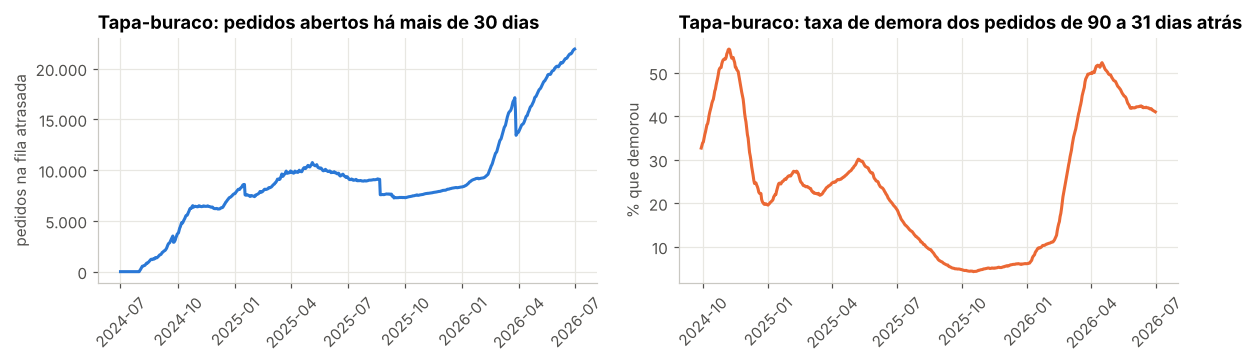

In [12]:
# Duas das séries que o modelo enxerga, para o serviço Tapa-buraco
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.4))
tb = serie_servico.xs("Tapa-buraco", level="servico")
eixos[0].plot(tb.index, tb["serv_fila_atrasada"], color=AZUL)
eixos[0].set_title("Tapa-buraco: pedidos abertos há mais de 30 dias")
eixos[0].set_ylabel("pedidos na fila atrasada")
eixos[0].yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
eixos[1].plot(tb.index, tb["serv_taxa_madura"] * 100, color=LARANJA)
eixos[1].set_title("Tapa-buraco: taxa de demora dos pedidos de 90 a 31 dias atrás")
eixos[1].set_ylabel("% que demorou")
for ax in eixos:
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "03b_series_temporais.png")
plt.show()

### 3.5 Entradas do modelo

Entram só informações que o SmartRoad tem **no momento do registro**:

| Entrada | Tipo | De onde vem no app |
| --- | --- | --- |
| `servico` | categórica (9) | tipo de ocorrência escolhido pelo cidadão |
| `canal` | categórica (4) | por onde o pedido chega (no SP156: MOBILE, PORTAL, CRM e CHATBOT; no SmartRoad seria sempre o app) |
| `subprefeitura` | categórica (33) | região da cidade, a partir da localização |
| `latitude`, `longitude` | numéricas | GPS do celular ou endereço |
| `dia_semana` | numérica | data do registro |
| 14 indicadores `serv_*` e `subp_*` | numéricas (série temporal) | histórico recente do serviço e da subprefeitura, Seção 3.4 |

Ficam **de fora**: o `mes` (com poucos anos de dados ele só serve de marcador de época e atrapalha: foi testado e piorou a validação mês a mês, Seção 6.4), `status`, `data_finalizacao` e `dias_ate_finalizar` do próprio pedido (são a resposta), `orgao` (pode mudar depois da abertura) e `distrito` (96 categorias que a latitude e a longitude já representam).

As variáveis categóricas passam por *one-hot encoding* (uma coluna 0/1 por categoria), como fizemos nos trabalhos do primeiro semestre.

In [13]:
dados["dia_semana"] = dados["data_abertura"].dt.dayofweek  # 0 = segunda ... 6 = domingo

NUMERICAS = ["latitude", "longitude", "dia_semana"]
CATEGORICAS = ["servico", "canal", "subprefeitura"]

X_base = pd.get_dummies(dados[NUMERICAS + CATEGORICAS], columns=CATEGORICAS, dtype=int)   # só o que vem do cadastro
X = pd.concat([X_base, historico], axis=1)                                                 # + série temporal
y = dados["demora"]

assert len(X) == len(dados) and X_base.isna().sum().sum() == 0  # nenhuma linha perdida, nenhum vazio no cadastro
# os únicos vazios são os indicadores de janela longa nos primeiros 90 dias da série (ainda sem histórico)
assert dados.loc[historico["serv_taxa_madura"].isna(), "data_abertura"].max() < dados["data_abertura"].min() + pd.Timedelta(days=95)
print(f"Matriz de entradas: {X.shape[0]:,} linhas x {X.shape[1]} colunas "
      f"({len(NUMERICAS)} numéricas + {X_base.shape[1] - len(NUMERICAS)} colunas 0/1 + {len(COLUNAS_TEMPORAIS)} de série temporal)".replace(",", "."))

Matriz de entradas: 384.139 linhas x 63 colunas (3 numéricas + 46 colunas 0/1 + 14 de série temporal)


### 3.6 Divisão treino / teste (por data, com intervalo)

- **Teste:** solicitações abertas de 01/05/2026 a 30/06/2026 (os 2 meses mais recentes).
- **Treino:** solicitações abertas de 01/07/2024 a 31/03/2026.
- **Intervalo de 30 dias (abril/2026):** fica de fora. Em 1º de maio, o desfecho de um pedido aberto em abril ainda **não é conhecido** (ele só se resolve em 30 dias). Treinar com esses pedidos seria usar informação do futuro. Com o intervalo, o treino é exatamente o que o modelo saberia em 1º de maio de 2026.

O teste fica guardado até a Seção 6. Toda escolha de hiperparâmetro é feita só com o treino.

In [14]:
CORTE = pd.Timestamp("2026-05-01")                 # primeiro dia do teste
FIM_TREINO = CORTE - pd.Timedelta(days=30)          # o desfecho de um pedido só é conhecido 30 dias depois
no_treino = dados["data_abertura"] < FIM_TREINO
no_teste = dados["data_abertura"] >= CORTE

X_treino, y_treino = X[no_treino], y[no_treino]
X_teste, y_teste = X[no_teste], y[no_teste]

divisao = pd.DataFrame({
    "período": ["01/07/2024 a 31/03/2026", "01/05/2026 a 30/06/2026"],
    "solicitações": [len(X_treino), len(X_teste)],
    "% do total": [round(len(X_treino) / len(X) * 100, 1), round(len(X_teste) / len(X) * 100, 1)],
    "% que demora": [round(y_treino.mean() * 100, 1), round(y_teste.mean() * 100, 1)],
}, index=["treino", "teste"])
display(divisao)

# Nenhum pedido do treino foi aberto menos de 30 dias antes do primeiro pedido do teste
assert (dados.loc[no_teste, "data_abertura"].min() - dados.loc[no_treino, "data_abertura"].max()).days >= 30

,período,solicitações,% do total,% que demora
treino,01/07/2024 a 31/03/2026,342311,89.1,34.0
teste,01/05/2026 a 30/06/2026,26459,6.9,42.1


## 4. Escolha do modelo: XGBoost

Entre as opções do enunciado (XGBoost, Random Forest, MLP, LSTM e KMeans + PCA), escolhemos o **XGBoost** (`XGBClassifier`):

- **Os dados são uma tabela** com variáveis categóricas e numéricas misturadas. Modelos de árvores costumam ser os melhores nesse formato e não exigem normalizar nada.
- **As relações não são lineares e se combinam**: o efeito da região depende do serviço e da época. Árvores capturam essas combinações sozinhas; a latitude e a longitude, por exemplo, viram "recortes" do mapa.
- **Temos rótulo**, então é um problema supervisionado. KMeans + PCA agrupa sem usar a resposta e não responde "vai demorar?".
- **A série temporal entra como entrada, não como arquitetura.** O que muda no tempo (fila, ritmo, taxa de demora recente) foi resumido em indicadores diários (Seção 3.4) que o XGBoost usa lado a lado com as demais colunas. Uma LSTM precisaria de uma sequência longa **por ocorrência**, e cada pedido tem um único ponto no tempo; a sequência existe por serviço e por região, e é isso que os indicadores já capturam. Uma MLP exigiria normalização e mais ajuste para, em tabelas assim, normalmente empatar ou perder para árvores.
- **Contra o Random Forest**, o XGBoost constrói as árvores em sequência, cada uma corrigindo os erros das anteriores, e tem controles diretos de complexidade (profundidade, taxa de aprendizado, número de árvores). Isso é útil aqui, porque o maior risco do problema é o modelo decorar o passado.
- Ele devolve uma **probabilidade**, que é o que o app precisa mostrar ao cidadão ("chance alta de demorar"), e treina em segundos ou poucos minutos com 350 mil linhas.

## 5. Treino com diferentes hiperparâmetros

Testamos **18 combinações de 3 hiperparâmetros** com `GridSearchCV`:

| Hiperparâmetro | Valores | O que controla |
| --- | --- | --- |
| `max_depth` | 3, 6, 9 | profundidade de cada árvore (quanto maior, mais detalhe e mais risco de decorar) |
| `learning_rate` | 0,03 · 0,1 · 0,3 | tamanho do passo de cada árvore nova |
| `n_estimators` | 100, 300 | quantidade de árvores |

**Validação cruzada só no treino.** Usamos `TimeSeriesSplit` com 4 divisões e um **intervalo (`gap`) equivalente a 30 dias**: o treino é cortado em 5 blocos em ordem de data e, em cada rodada, o modelo treina nos blocos mais antigos e é validado no bloco seguinte, pulando os 30 dias entre eles (pelo mesmo motivo do intervalo da Seção 3.6). É a mesma lógica da divisão treino/teste (aprender com o passado, prever o futuro), e o conjunto de teste não participa.

**Métrica da busca:** AUC-ROC, que mede se o modelo dá probabilidade maior para as solicitações que realmente demoram. Ela não depende de um ponto de corte e não se deixa enganar pela mudança na proporção de demoras ao longo do tempo.

In [15]:
GAP = int(30 * len(X_treino) / (FIM_TREINO - dados["data_abertura"].min()).days)  # 30 dias, em número de linhas
grade = {
    "max_depth": [3, 6, 9],
    "learning_rate": [0.03, 0.1, 0.3],
    "n_estimators": [100, 300],
}

busca = GridSearchCV(
    estimator=XGBClassifier(tree_method="hist", random_state=SEMENTE, n_jobs=4),
    param_grid=grade,
    scoring="roc_auc",
    cv=TimeSeriesSplit(n_splits=4, gap=GAP),   # só dentro do treino, sempre validando em datas posteriores a 30 dias do fim do bloco de treino
    return_train_score=True,          # guarda também a nota no treino, para medir o overfitting
)
busca.fit(X_treino, y_treino)

print(f"Combinações testadas: {len(busca.cv_results_['params'])} (x 4 divisões = {len(busca.cv_results_['params']) * 4} treinos)")
print(f"Melhor combinação: {busca.best_params_} | AUC média na validação: {busca.best_score_:.3f}")

Combinações testadas: 18 (x 4 divisões = 72 treinos)
Melhor combinação: {'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 300} | AUC média na validação: 0.800


In [16]:
# Todas as combinações, da melhor para a pior na validação
resultados = pd.DataFrame(busca.cv_results_["params"])
resultados["AUC treino"] = busca.cv_results_["mean_train_score"]
resultados["AUC validação"] = busca.cv_results_["mean_test_score"]
resultados["desvio validação"] = busca.cv_results_["std_test_score"]
resultados["diferença (treino - validação)"] = resultados["AUC treino"] - resultados["AUC validação"]
resultados = resultados.sort_values("AUC validação", ascending=False).reset_index(drop=True)
resultados.index += 1
resultados.round(3)

,learning_rate,max_depth,n_estimators,AUC treino,AUC validação,desvio validação,diferença (treino - validação)
1,0.03,6,300,0.872,0.800,0.055,0.071
2,0.10,6,100,0.874,0.793,0.056,0.082
3,0.10,3,300,0.854,0.793,0.053,0.062
4,0.03,9,300,0.912,0.792,0.056,0.120
5,0.03,9,100,0.886,0.791,0.057,0.095
6,0.30,3,100,0.856,0.790,0.057,0.067
7,0.10,9,100,0.916,0.790,0.059,0.126
8,0.03,6,100,0.851,0.789,0.060,0.061
9,0.10,9,300,0.953,0.786,0.056,0.167
10,0.03,3,300,0.828,0.786,0.055,0.043


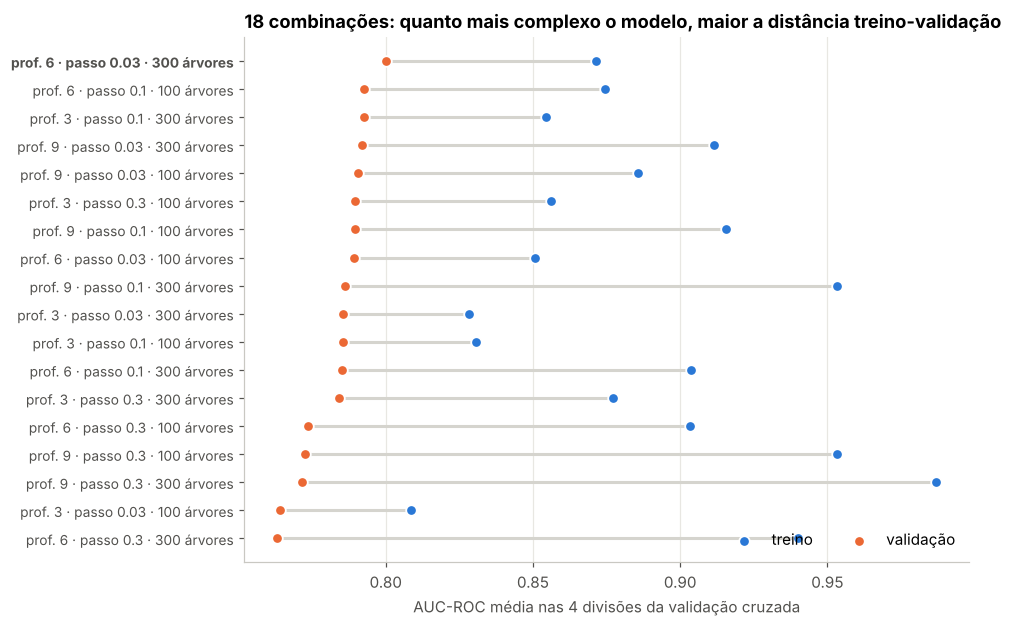

In [17]:
# Treino x validação em cada combinação: a distância entre os pontos é o overfitting
ordem = resultados.iloc[::-1]
nomes = [f"prof. {int(p)} · passo {t} · {int(n)} árvores"
         for p, t, n in zip(ordem["max_depth"], ordem["learning_rate"], ordem["n_estimators"])]
posicoes = np.arange(len(ordem))

fig, ax = plt.subplots(figsize=(8.5, 6.2))
ax.hlines(posicoes, ordem["AUC validação"], ordem["AUC treino"], color="#d5d4ce", linewidth=2, zorder=1)
ax.scatter(ordem["AUC treino"], posicoes, color=AZUL, s=48, zorder=2, edgecolor="white", linewidth=1.2, label="treino")
ax.scatter(ordem["AUC validação"], posicoes, color=LARANJA, s=48, zorder=2, edgecolor="white", linewidth=1.2, label="validação")
ax.set_yticks(posicoes, nomes, fontsize=9)
ax.get_yticklabels()[-1].set_fontweight("bold")  # a escolhida fica no topo
ax.set_xlabel("AUC-ROC média nas 4 divisões da validação cruzada")
ax.set_title("18 combinações: quanto mais complexo o modelo, maior a distância treino-validação")
ax.legend(loc="lower right", ncols=2)
ax.grid(axis="y", visible=False)
fig.savefig(PASTA_FIGURAS / "04_busca_hiperparametros.png")
plt.show()

**Leitura da busca**

- **Combinação escolhida:** `max_depth=6`, `learning_rate=0.03`, `n_estimators=300`, com AUC média de 0,800 na validação. A regra (maior AUC média na validação) foi definida antes de olhar o teste.
- **É quase um empate:** as 7 primeiras combinações ficam entre 0,790 e 0,800, uma diferença bem menor que o desvio entre as divisões (0,05 a 0,06). Qualquer uma delas serviria. O desvio é alto porque cada divisão valida em uma época diferente, e as épocas não são iguais (gráfico da Seção 3.3).
- **Dá para ver o overfitting acontecendo:** em todas as combinações o treino (0,81 a 0,99) fica acima da validação (0,76 a 0,80). A mais complexa da grade (profundidade 9, passo 0,3, 300 árvores) chega a 0,987 no treino e fica entre as piores na validação (0,772): ela decorou o treino. A mais simples (profundidade 3, passo 0,03, 100 árvores) tem uma das menores distâncias (0,044), mas também uma das piores validações (0,764): aprendeu de menos. A escolhida é de complexidade média: profundidade 6, com passo pequeno e mais árvores.
- Aumentar a complexidade além do ponto escolhido só melhora a nota do treino. É o sinal para parar.

## 6. Resultados em treino e teste

O `GridSearchCV` já retreinou a melhor combinação com **todo** o treino. Agora, pela primeira vez, o modelo vê o conjunto de teste (maio e junho de 2026), que vem depois do intervalo de 30 dias descrito na Seção 3.6.

Métricas usadas, e por quê:

- **AUC-ROC:** qualidade da ordenação das probabilidades (0,5 = sorteio; 1,0 = perfeito).
- **Acurácia** e **acurácia balanceada:** acertos no total e a média dos acertos em cada classe. A balanceada evita a ilusão de acertar muito só por chutar a classe mais comum.
- **Precisão, recall e F1 da classe "demora":** quando o modelo avisa que vai demorar, quantas vezes acerta (precisão); das que demoraram, quantas ele avisou (recall); F1 resume as duas.
- **Escore de Brier** (Seção 6.4): erro quadrático médio da probabilidade. Como o app mostra a chance ao cidadão, ela precisa estar bem calibrada, e não só bem ordenada.
- **Linha de base:** um "modelo" que sempre responde "não vai demorar". Se o XGBoost não ganhar disso, não serve.

In [18]:
modelo = busca.best_estimator_

def avaliar(X_parte, y_parte):
    # Calcula todas as métricas de uma parte (treino ou teste) com ponto de corte de 50%
    prob = modelo.predict_proba(X_parte)[:, 1]
    previsto = (prob >= 0.5).astype(int)
    return {
        "AUC-ROC": roc_auc_score(y_parte, prob),
        "Acurácia": accuracy_score(y_parte, previsto),
        "Acurácia balanceada": balanced_accuracy_score(y_parte, previsto),
        "Precisão (demora)": precision_score(y_parte, previsto),
        "Recall (demora)": recall_score(y_parte, previsto),
        "F1 (demora)": f1_score(y_parte, previsto),
    }

metricas = pd.DataFrame({"treino": avaliar(X_treino, y_treino), "teste": avaliar(X_teste, y_teste)})
metricas["diferença"] = metricas["treino"] - metricas["teste"]

# Linha de base: responder sempre "não vai demorar"
base_treino, base_teste = 1 - y_treino.mean(), 1 - y_teste.mean()
print(f"Linha de base (sempre 'não demora'): acurácia {base_treino:.3f} no treino e {base_teste:.3f} no teste; "
      "acurácia balanceada 0.500; recall 0.000")
metricas.round(3)

Linha de base (sempre 'não demora'): acurácia 0.660 no treino e 0.579 no teste; acurácia balanceada 0.500; recall 0.000


,treino,teste,diferença
AUC-ROC,0.872,0.724,0.148
Acurácia,0.801,0.681,0.120
Acurácia balanceada,0.756,0.654,0.103
Precisão (demora),0.753,0.668,0.085
Recall (demora),0.616,0.481,0.135
F1 (demora),0.678,0.559,0.118


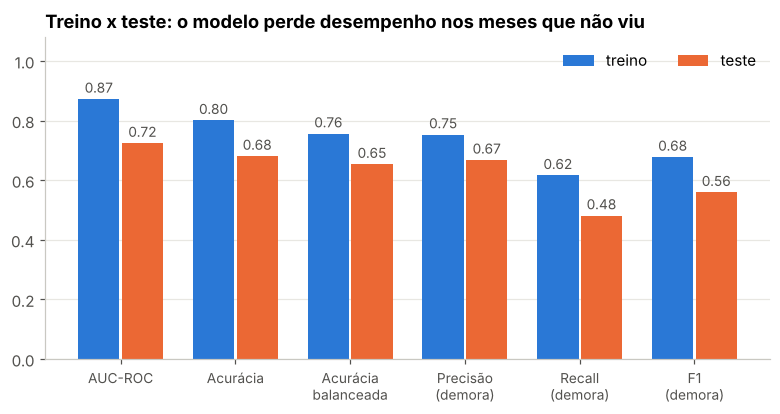

In [19]:
# Métricas de treino e teste lado a lado
fig, ax = plt.subplots(figsize=(8.5, 3.8))
posicoes = np.arange(len(metricas))
largura = 0.36
barras_treino = ax.bar(posicoes - largura / 2 - 0.01, metricas["treino"], largura, color=AZUL, label="treino")
barras_teste = ax.bar(posicoes + largura / 2 + 0.01, metricas["teste"], largura, color=LARANJA, label="teste")
for barras in (barras_treino, barras_teste):
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=9, color=TEXTO)
ax.set_xticks(posicoes, [m.replace(" (", "\n(").replace("Acurácia b", "Acurácia\nb") for m in metricas.index], fontsize=9)
ax.set_ylim(0, 1.08)
ax.set_title("Treino x teste: o modelo perde desempenho nos meses que não viu")
ax.legend(loc="upper right", ncols=2)
ax.grid(axis="x", visible=False)
fig.savefig(PASTA_FIGURAS / "05_metricas_treino_teste.png")
plt.show()

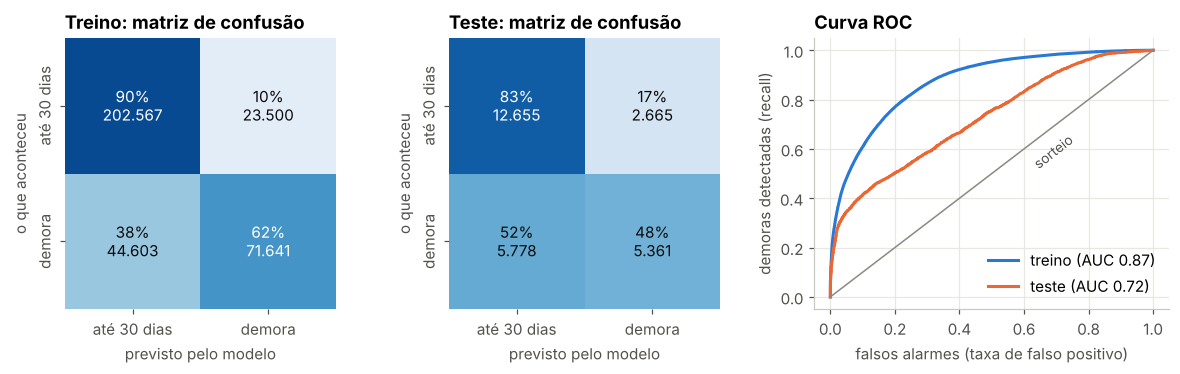

In [20]:
# Matriz de confusão (em % de cada linha) e curva ROC, treino e teste
prob_treino = modelo.predict_proba(X_treino)[:, 1]
prob_teste = modelo.predict_proba(X_teste)[:, 1]

fig, eixos = plt.subplots(1, 3, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1, 1, 1.15]})
classes = ["até 30 dias", "demora"]
for ax, nome, y_parte, prob in [(eixos[0], "Treino", y_treino, prob_treino), (eixos[1], "Teste", y_teste, prob_teste)]:
    matriz = confusion_matrix(y_parte, (prob >= 0.5).astype(int))
    proporcao = matriz / matriz.sum(axis=1, keepdims=True)
    ax.imshow(proporcao, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{proporcao[i, j]:.0%}\n{matriz[i, j]:,}".replace(",", "."), ha="center", va="center",
                    color="white" if proporcao[i, j] > 0.55 else "#0b0b0b", fontsize=10)
    ax.set_xticks([0, 1], classes); ax.set_yticks([0, 1], classes, rotation=90, va="center")
    ax.set_xlabel("previsto pelo modelo"); ax.set_ylabel("o que aconteceu")
    ax.set_title(f"{nome}: matriz de confusão")
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)

ax = eixos[2]
for nome, y_parte, prob, cor in [("treino", y_treino, prob_treino, AZUL), ("teste", y_teste, prob_teste, LARANJA)]:
    falso_positivo, verdadeiro_positivo, _ = roc_curve(y_parte, prob)
    ax.plot(falso_positivo, verdadeiro_positivo, color=cor, label=f"{nome} (AUC {roc_auc_score(y_parte, prob):.2f})")
ax.plot([0, 1], [0, 1], color=CINZA, linewidth=1)
ax.text(0.62, 0.52, "sorteio", color=TEXTO, fontsize=9, rotation=38)
ax.set_xlabel("falsos alarmes (taxa de falso positivo)"); ax.set_ylabel("demoras detectadas (recall)")
ax.set_title("Curva ROC")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "06_confusao_e_roc.png")
plt.show()

### 6.1 Por que dividir por data? O mesmo modelo com divisão por sorteio

Só para comparação, treinamos os mesmos hiperparâmetros com uma divisão **aleatória** do mesmo tamanho. Esse número não é o resultado do trabalho: ele mostra o quanto uma divisão por sorteio enfeitaria a nota.

In [21]:
Xa_treino, Xa_teste, ya_treino, ya_teste = train_test_split(
    X, y, test_size=len(X_teste), stratify=y, random_state=SEMENTE)

modelo_sorteio = XGBClassifier(**busca.best_params_, tree_method="hist", random_state=SEMENTE, n_jobs=4)
modelo_sorteio.fit(Xa_treino, ya_treino)

comparacao = pd.DataFrame({
    "divisão por data (a que usamos)": [metricas.loc["AUC-ROC", "treino"], metricas.loc["AUC-ROC", "teste"]],
    "divisão por sorteio": [roc_auc_score(ya_treino, modelo_sorteio.predict_proba(Xa_treino)[:, 1]),
                             roc_auc_score(ya_teste, modelo_sorteio.predict_proba(Xa_teste)[:, 1])],
}, index=["AUC treino", "AUC teste"])
comparacao.round(3)

,divisão por data (a que usamos),divisão por sorteio
AUC treino,0.872,0.864
AUC teste,0.724,0.858


### 6.2 A probabilidade do modelo é confiável?

Para o cidadão, o que aparece no app é uma chance de demora. Então conferimos, no teste: quando o modelo diz "30%", demora em 30% dos casos?

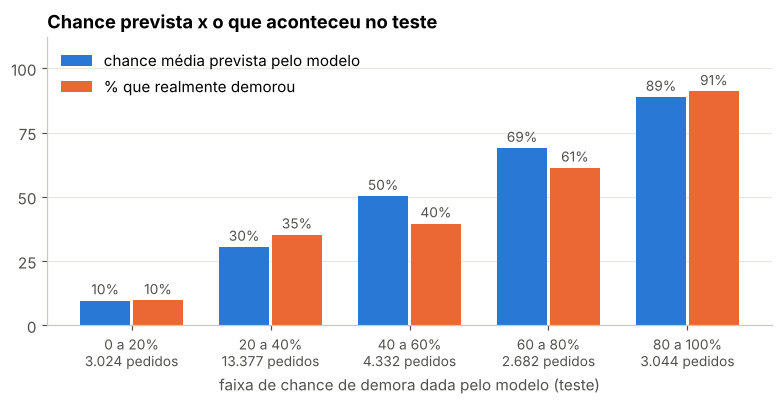

,solicitacoes,chance_media_prevista,demora_real
faixa,,,
0 a 20%,3024,0.097,0.097
20 a 40%,13377,0.305,0.353
40 a 60%,4332,0.503,0.396
60 a 80%,2682,0.689,0.613
80 a 100%,3044,0.888,0.910


In [22]:
faixas = pd.cut(prob_teste, bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True,
                labels=["0 a 20%", "20 a 40%", "40 a 60%", "60 a 80%", "80 a 100%"])
confianca = pd.DataFrame({"faixa": faixas, "prevista": prob_teste, "real": y_teste.values}).groupby("faixa", observed=True).agg(
    solicitacoes=("real", "size"), chance_media_prevista=("prevista", "mean"), demora_real=("real", "mean"))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
posicoes = np.arange(len(confianca))
barras_prev = ax.bar(posicoes - 0.19, confianca["chance_media_prevista"] * 100, 0.36, color=AZUL, label="chance média prevista pelo modelo")
barras_real = ax.bar(posicoes + 0.19, confianca["demora_real"] * 100, 0.36, color=LARANJA, label="% que realmente demorou")
for barras in (barras_prev, barras_real):
    ax.bar_label(barras, fmt="%.0f%%", padding=2, fontsize=9, color=TEXTO)
ax.set_xticks(posicoes, [f"{f}\n{n:,} pedidos".replace(",", ".") for f, n in zip(confianca.index, confianca["solicitacoes"])], fontsize=9)
ax.set_ylim(0, 112); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xlabel("faixa de chance de demora dada pelo modelo (teste)")
ax.set_title("Chance prevista x o que aconteceu no teste")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
fig.savefig(PASTA_FIGURAS / "07_confianca_das_probabilidades.png")
plt.show()

confianca.astype({"chance_media_prevista": float}).round(3)

### 6.3 O que mais pesa na previsão

Em laranja, os indicadores da série temporal (Seção 3.4). Somados, eles respondem por 80% do ganho do modelo, e só a `taxa_madura` (a taxa de demora recente do serviço) por 48%. O serviço e a região ainda contam (subprefeitura 9%, latitude e longitude 6% juntas, serviço 5%), mas boa parte do que eles sabiam agora vem do histórico recente: se o serviço está atrasado hoje, o pedido novo tende a atrasar. Canal e dia da semana pesam menos de 1% somados.

Série temporal (14 indicadores juntos): 80.2% do ganho
{'série temporal: taxa_madura': 48.2, 'subprefeitura': 8.6, 'série temporal: fila_atrasada': 8.3, 'série temporal: tendencia': 7.1, 'série temporal: ritmo30': 6.5, 'série temporal: vol30': 4.9, 'servico': 4.7, 'série temporal: fila': 3.5, 'latitude': 3.1, 'longitude': 3.0, 'série temporal: vol7': 1.7, 'canal': 0.3, 'dia_semana': 0.1}


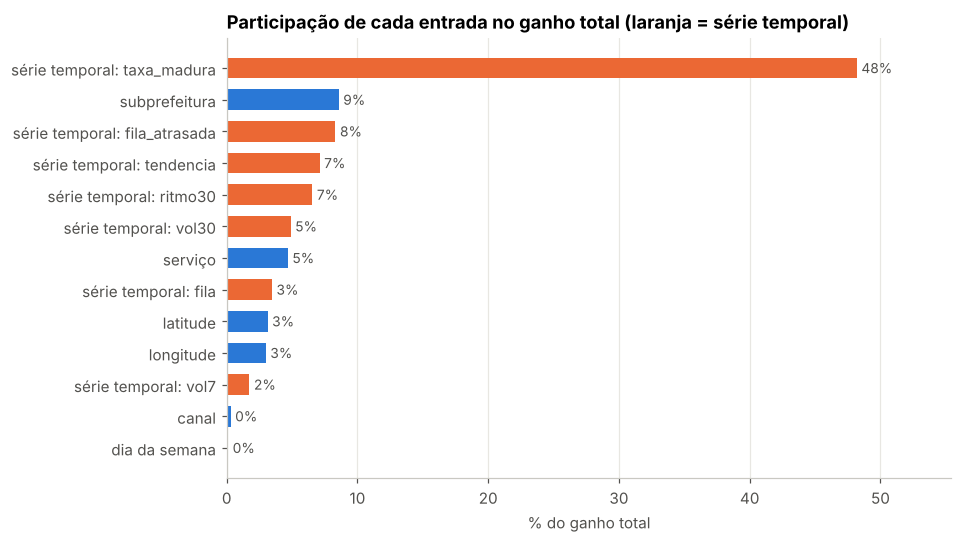

In [23]:
# Importância por ganho: quanto cada entrada ajuda a separar as classes nas árvores.
# As colunas 0/1 de uma mesma variável categórica são somadas para dar a importância da variável inteira,
# e os 14 indicadores de série temporal são mostrados juntos e também por tipo.
ganho = pd.Series(modelo.get_booster().get_score(importance_type="total_gain"))
def nome_da_entrada(coluna):
    if coluna in COLUNAS_TEMPORAIS:
        return "série temporal: " + coluna.split("_", 1)[1]
    return next((c for c in CATEGORICAS if coluna.startswith(c + "_")), coluna)
grupo = ganho.index.to_series().apply(nome_da_entrada)
importancia = (ganho.groupby(grupo).sum() / ganho.sum() * 100)
total_temporal = importancia[importancia.index.str.startswith("série temporal")].sum()
print(f"Série temporal (14 indicadores juntos): {total_temporal:.1f}% do ganho")
print(importancia.round(1).sort_values(ascending=False).to_dict())
importancia = importancia.sort_values()
NOMES = {"servico": "serviço", "dia_semana": "dia da semana"}
importancia.index = [NOMES.get(i, i) for i in importancia.index]

cores = [LARANJA if i.startswith("série temporal") else AZUL for i in importancia.index]
fig, ax = plt.subplots(figsize=(8.5, 5.2))
barras = ax.barh(importancia.index, importancia.values, color=cores, height=0.65)
ax.bar_label(barras, fmt="%.0f%%", padding=3, fontsize=9, color=TEXTO)
ax.set_xlim(0, importancia.max() * 1.15)
ax.set_title("Participação de cada entrada no ganho total (laranja = série temporal)")
ax.set_xlabel("% do ganho total")
ax.grid(axis="y", visible=False)
fig.savefig(PASTA_FIGURAS / "08_importancia_das_entradas.png")
plt.show()

### 6.4 A série temporal ajuda? Comparação mês a mês (walk-forward) e contra uma previsão ingênua

Para responder à pergunta do professor com evidência, comparamos **três previsores nos mesmos pedidos e nas mesmas condições**:

1. **Persistência (ingênuo):** diz que a chance de demora de um pedido novo é a taxa de demora recente do serviço (`serv_taxa_madura`), sem aprender nada.
2. **XGBoost sem série temporal:** só o que vem do cadastro do pedido (serviço, canal, região, coordenadas, dia da semana).
3. **XGBoost com série temporal:** o modelo final.

Primeiro no teste final (maio e junho de 2026) e depois em **walk-forward**: para cada um dos 12 meses de jul/2025 a jun/2026, o modelo é treinado só com pedidos abertos até 30 dias antes do início do mês e testado naquele mês. É a forma honesta de simular o uso real, com retreino mensal, e mostra se o ganho aparece em todas as épocas ou só em uma. Além da AUC, usamos o **escore de Brier** (erro quadrático médio da probabilidade; quanto menor, melhor), porque o app mostra a probabilidade ao cidadão.

In [24]:
def brier(y_real, prob):
    return float(np.mean((prob - y_real) ** 2))

# --- Teste final: maio e junho de 2026 ---
modelo_sem_serie = XGBClassifier(**busca.best_params_, tree_method="hist", random_state=SEMENTE, n_jobs=4)
modelo_sem_serie.fit(X_treino[X_base.columns], y_treino)
prob_sem_serie = modelo_sem_serie.predict_proba(X_teste[X_base.columns])[:, 1]
prob_persistencia = X_teste["serv_taxa_madura"].fillna(y_treino.mean()).to_numpy()
prob_com_serie = modelo.predict_proba(X_teste)[:, 1]

comparacao_teste = pd.DataFrame({
    "persistência (ingênuo)": prob_persistencia,
    "XGBoost sem série temporal": prob_sem_serie,
    "XGBoost com série temporal": prob_com_serie,
}).apply(lambda p: pd.Series({
    "AUC-ROC": roc_auc_score(y_teste, p),
    "Acurácia (corte 50%)": accuracy_score(y_teste, p >= 0.5),
    "Brier (menor é melhor)": brier(y_teste.to_numpy(), p.to_numpy()),
    "Chance média prevista": p.mean(),
})).T
comparacao_teste["Demora real no teste"] = y_teste.mean()
comparacao_teste.round(3)

,AUC-ROC,Acurácia (corte 50%),Brier (menor é melhor),Chance média prevista,Demora real no teste
persistência (ingênuo),0.702,0.673,0.209,0.472,0.421
XGBoost sem série temporal,0.717,0.694,0.205,0.350,0.421
XGBoost com série temporal,0.724,0.681,0.200,0.419,0.421


In [25]:
# --- Walk-forward: 12 meses, retreinando a cada mês ---
meses = pd.period_range("2025-07", "2026-06", freq="M")
linhas = []
for mes in meses:
    inicio, fim = mes.start_time, mes.end_time.normalize()
    treino_m = dados["data_abertura"] < inicio - pd.Timedelta(days=30)   # só o que já tinha desfecho conhecido
    teste_m = (dados["data_abertura"] >= inicio) & (dados["data_abertura"] <= fim)
    p = {}
    p["persistência"] = X.loc[teste_m, "serv_taxa_madura"].fillna(y[treino_m].mean()).to_numpy()
    for nome, colunas in [("sem série temporal", X_base.columns), ("com série temporal", X.columns)]:
        m = XGBClassifier(**busca.best_params_, tree_method="hist", random_state=SEMENTE, n_jobs=4)
        m.fit(X.loc[treino_m, colunas], y[treino_m])
        p[nome] = m.predict_proba(X.loc[teste_m, colunas])[:, 1]
    linha = {"mês": f"{mes.month:02d}/{mes.year}", "pedidos": int(teste_m.sum()), "demora real": y[teste_m].mean()}
    for nome, prob in p.items():
        linha[f"AUC {nome}"] = roc_auc_score(y[teste_m], prob)
        linha[f"Brier {nome}"] = brier(y[teste_m].to_numpy(), prob)
        linha[f"viés {nome}"] = prob.mean() - y[teste_m].mean()
    linhas.append(linha)
walk = pd.DataFrame(linhas).set_index("mês")

resumo_walk = pd.DataFrame({
    "AUC média": [walk[f"AUC {n}"].mean() for n in ["persistência", "sem série temporal", "com série temporal"]],
    "Brier médio": [walk[f"Brier {n}"].mean() for n in ["persistência", "sem série temporal", "com série temporal"]],
    "erro médio da chance média (|viés|)": [walk[f"viés {n}"].abs().mean() for n in ["persistência", "sem série temporal", "com série temporal"]],
    "meses em que a AUC foi maior que a de 'sem série'": [(walk[f"AUC {n}"] > walk["AUC sem série temporal"]).sum() for n in ["persistência", "sem série temporal", "com série temporal"]],
}, index=["persistência (ingênuo)", "XGBoost sem série temporal", "XGBoost com série temporal"])
display(resumo_walk.round(3))
walk[[c for c in walk.columns if c.startswith("AUC")]].round(3)

,AUC média,Brier médio,erro médio da chance média (|viés|),meses em que a AUC foi maior que a de 'sem série'
persistência (ingênuo),0.777,0.175,0.073,3
XGBoost sem série temporal,0.782,0.177,0.109,0
XGBoost com série temporal,0.794,0.169,0.066,9


,AUC persistência,AUC sem série temporal,AUC com série temporal
mês,,,
07/2025,0.851,0.854,0.890
08/2025,0.864,0.859,0.894
09/2025,0.841,0.801,0.837
10/2025,0.845,0.855,0.884
11/2025,0.846,0.872,0.888
12/2025,0.760,0.816,0.811
01/2026,0.786,0.734,0.748
02/2026,0.723,0.726,0.717
03/2026,0.711,0.714,0.701


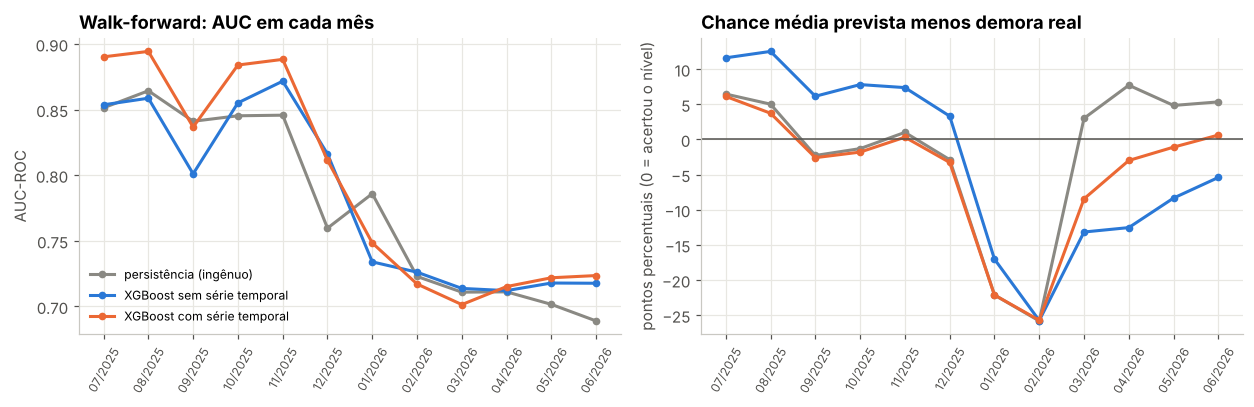

In [26]:
fig, eixos = plt.subplots(1, 2, figsize=(11.5, 3.8))
rotulos = list(walk.index)
estilo = [("persistência", CINZA, "persistência (ingênuo)"), ("sem série temporal", AZUL, "XGBoost sem série temporal"),
          ("com série temporal", LARANJA, "XGBoost com série temporal")]
for nome, cor, legenda in estilo:
    eixos[0].plot(rotulos, walk[f"AUC {nome}"], color=cor, marker="o", markersize=4, label=legenda)
    eixos[1].plot(rotulos, walk[f"viés {nome}"] * 100, color=cor, marker="o", markersize=4, label=legenda)
eixos[0].set_title("Walk-forward: AUC em cada mês")
eixos[0].set_ylabel("AUC-ROC")
eixos[1].axhline(0, color=TEXTO, linewidth=1)
eixos[1].set_title("Chance média prevista menos demora real")
eixos[1].set_ylabel("pontos percentuais (0 = acertou o nível)")
for ax in eixos:
    ax.tick_params(axis="x", labelrotation=60, labelsize=8)
eixos[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "09_walk_forward.png")
plt.show()

In [27]:
# Teste extra: o mês do calendário ajuda ou atrapalha? (mesma lógica do walk-forward, só com 'mes' no lugar da série temporal)
X_com_mes = X_base.assign(mes=dados["data_abertura"].dt.month)
aucs_mes = []
for mes in meses:
    inicio, fim = mes.start_time, mes.end_time.normalize()
    treino_m = dados["data_abertura"] < inicio - pd.Timedelta(days=30)
    teste_m = (dados["data_abertura"] >= inicio) & (dados["data_abertura"] <= fim)
    m = XGBClassifier(**busca.best_params_, tree_method="hist", random_state=SEMENTE, n_jobs=4)
    m.fit(X_com_mes[treino_m], y[treino_m])
    aucs_mes.append(roc_auc_score(y[teste_m], m.predict_proba(X_com_mes[teste_m])[:, 1]))
print(f"AUC média no walk-forward com o mês do calendário (sem série temporal): {np.mean(aucs_mes):.3f}")
print(f"AUC média sem o mês e sem série temporal: {walk['AUC sem série temporal'].mean():.3f}")
print(f"AUC média com série temporal: {walk['AUC com série temporal'].mean():.3f}")

AUC média no walk-forward com o mês do calendário (sem série temporal): 0.756
AUC média sem o mês e sem série temporal: 0.782
AUC média com série temporal: 0.794


### 6.5 Leitura dos resultados e discussão de overfitting

**O modelo aprendeu algo que vale para meses que ele não viu.** No teste, a AUC é 0,724 e a acurácia é 0,681, contra 0,579 de quem sempre responde "não demora" (ganho de 10,2 pontos). A acurácia balanceada sai de 0,500 para 0,654.

**Existe overfitting, e ele é relevante.** A AUC cai de 0,872 no treino para 0,724 no teste (0,148 de diferença) e o F1 da classe "demora" cai de 0,678 para 0,559. Vemos duas causas:

1. **Árvores profundas decoram detalhes do treino.** Com profundidade 6 e 300 árvores o modelo ainda guarda detalhes de cada região e de cada época.
2. **A cidade mudou de regime.** A taxa de demora passou de 34,0% no treino para 42,1% no teste, depois do salto de janeiro de 2026 (Seção 3.3). O teste cai bem no meio do período mais difícil de prever.

A validação cruzada estimou 0,800 e o teste deu 0,724. A diferença tem a mesma origem: no walk-forward da Seção 6.4 o modelo chega a 0,89 em meses calmos (jul/2025) e fica entre 0,70 e 0,75 depois do salto de regime (jan a jun/2026). Ainda assim, a validação foi um aviso bem mais honesto do que a nota do treino.

**A divisão por sorteio enfeitaria o resultado.** Com os mesmos hiperparâmetros, ela daria AUC de 0,858 no teste (Seção 6.1), 0,13 a mais. Misturar dias da mesma semana no treino e no teste deixa o modelo "conhecer" o ritmo de cada época, coisa que o app nunca vai ter na hora de prever uma ocorrência nova. O número que vale é o da divisão por data.

**A série temporal ajuda, mas pouco, e não em todos os meses (Seção 6.4).** No walk-forward de 12 meses, o modelo com série temporal tem AUC média de 0,794 contra 0,782 do modelo sem ela e 0,777 da previsão ingênua por persistência. O ganho aparece em 9 dos 12 meses, é maior em jul a out/2025 (cerca de +0,03 a +0,04) e desaparece em fev e mar/2026, logo depois do salto de regime. Onde a série temporal mais ajuda é no **nível** da probabilidade: o erro médio da chance média prevista cai de 10,9 para 6,6 pontos percentuais, e o escore de Brier de 0,177 para 0,169. No teste final, a diferença é pequena (AUC 0,724 contra 0,717; Brier 0,200 contra 0,205), e a persistência sozinha já chega a 0,702. Ou seja: o histórico recente é o que mais pesa no modelo, mas um salto de regime como o de janeiro de 2026 ninguém consegue antecipar só olhando para trás.

**O mês do calendário atrapalha.** Trocar a série temporal pelo número do mês fez a AUC média cair para 0,756, abaixo até do modelo sem nada disso (0,782). Com apenas dois anos de dados, o mês só serve de marcador de época. Por isso ele não é entrada do modelo.

**O ponto fraco é o recall (0,48).** Com corte em 50%, o modelo deixa passar mais da metade das demoras. Quando ele avisa que vai demorar, acerta 2 em cada 3 vezes (precisão 0,67).

**As probabilidades são razoavelmente confiáveis.** Na maior parte das faixas a chance média prevista fica a menos de 8 pontos percentuais do que aconteceu, e o maior desvio é de cerca de 10 pontos, na faixa de 40 a 60% (previu 50%, demorou 40%; Seção 6.2). Por isso faz mais sentido o app mostrar faixas de chance do que um "sim" ou "não".

**Limitação dos dados.** O arquivo do 1º trimestre de 2025 chega com 1.048.575 linhas, exatamente o limite de linhas de uma planilha Excel, o que sugere que a Prefeitura o exportou por esse caminho e pode ter perdido linhas. Conferimos que os dias do fim do trimestre aparecem normalmente, mas não temos como garantir que esse trimestre esteja completo.

## 7. O que o resultado significa para o cidadão

### 7.1 Como o SmartRoad usaria o modelo

A função abaixo recebe exatamente o que o app tem quando o cidadão toca em "Registrar" e devolve a chance de demora. Para não inventar exemplos, usamos **seis solicitações reais do período de teste**, duas de cada tipo do app, e comparamos a previsão com o que de fato aconteceu.

In [28]:
def prever_demora(servico, canal, subprefeitura, latitude, longitude, data):
    # Chance (0 a 1) de uma ocorrência registrada agora demorar mais de 30 dias.
    # Além do que o cidadão informa, usa as séries do dia (Seção 3.4), que o backend atualiza uma vez por dia.
    data = pd.Timestamp(data)
    linha = pd.DataFrame([{"latitude": latitude, "longitude": longitude, "dia_semana": data.dayofweek,
                           "servico": servico, "canal": canal, "subprefeitura": subprefeitura}])
    entrada = pd.get_dummies(linha, columns=CATEGORICAS, dtype=int).reindex(columns=X_base.columns, fill_value=0)
    series_do_dia = pd.concat([serie_servico.loc[[(servico, data)]].reset_index(drop=True),
                               serie_subprefeitura.loc[[(subprefeitura, data)]].reset_index(drop=True)], axis=1)
    entrada = pd.concat([entrada, series_do_dia], axis=1)[X.columns]
    return float(modelo.predict_proba(entrada)[0, 1])

def mensagem_para_o_cidadao(chance):
    if chance < 0.4:
        return "Pedidos como este costumam ser finalizados em até 30 dias."
    if chance < 0.6:
        return "Não dá para afirmar: pedidos como este ficam perto de meio a meio."
    return "Pedidos como este costumam passar de 30 dias. Vale acompanhar pelo app."

# Duas solicitações reais do teste para cada tipo do SmartRoad (sorteadas com a mesma semente)
teste = dados[no_teste]
exemplos = teste.groupby("tipo_smartroad").sample(2, random_state=SEMENTE)

linhas = []
for _, e in exemplos.iterrows():
    chance = prever_demora(e["servico"], e["canal"], e["subprefeitura"], e["latitude"], e["longitude"], e["data_abertura"])
    aconteceu = "ainda aberta na extração" if pd.isna(e["dias_ate_finalizar"]) else f"finalizada em {e['dias_ate_finalizar']:.0f} dia(s)"
    linhas.append({"tipo no app": e["tipo_smartroad"], "serviço SP156": NOME_CURTO[e["servico"]],
                   "subprefeitura": e["subprefeitura"].title(), "aberta em": f"{e['data_abertura']:%d/%m/%Y}",
                   "chance de demora": f"{chance:.0%}", "mensagem no app": mensagem_para_o_cidadao(chance),
                   "o que aconteceu": aconteceu})
pd.DataFrame(linhas)

,tipo no app,serviço SP156,subprefeitura,aberta em,chance de demora,mensagem no app,o que aconteceu
0,Bueiro,Limpeza de bueiro e boca de lobo,Campo Limpo,31/05/2026,8%,Pedidos como este costumam ser finalizados em até 30 dias.,finalizada em 1 dia(s)
1,Bueiro,Limpeza de bueiro e boca de lobo,Ipiranga,24/06/2026,24%,Pedidos como este costumam ser finalizados em até 30 dias.,finalizada em 2 dia(s)
2,Buraco,Tapa-buraco,Lapa,13/05/2026,49%,Não dá para afirmar: pedidos como este ficam perto de meio a meio.,ainda aberta na extração
3,Buraco,Tapa-buraco,Ipiranga,29/06/2026,39%,Pedidos como este costumam ser finalizados em até 30 dias.,ainda aberta na extração
4,Calçada,Calçada particular danificada,Ipiranga,16/05/2026,90%,Pedidos como este costumam passar de 30 dias. Vale acompanhar pelo app.,ainda aberta na extração
5,Calçada,Calçada particular danificada,Jacana-Tremembe,05/05/2026,87%,Pedidos como este costumam passar de 30 dias. Vale acompanhar pelo app.,finalizada em 50 dia(s)


### 7.2 O modelo acerta o retrato de cada tipo de ocorrência?

In [29]:
# No teste: chance média prevista x demora real, por tipo do SmartRoad
retrato = teste.assign(chance_prevista=prob_teste).groupby("tipo_smartroad").agg(
    solicitacoes=("demora", "size"), chance_media_prevista=("chance_prevista", "mean"), demora_real=("demora", "mean"))
retrato[["chance_media_prevista", "demora_real"]] = (retrato[["chance_media_prevista", "demora_real"]].astype(float) * 100).round(1)
display(retrato)

# E as três mensagens do app: quantas vezes cada uma apareceria no teste e o que aconteceu de fato
por_mensagem = pd.DataFrame({"mensagem": [mensagem_para_o_cidadao(p) for p in prob_teste], "demora": y_teste.values}).groupby("mensagem").agg(
    solicitacoes=("demora", "size"), demora_real=("demora", "mean")).sort_values("demora_real")
por_mensagem["% do teste"] = (por_mensagem["solicitacoes"] / len(y_teste) * 100).round(1)
por_mensagem["demora_real"] = (por_mensagem["demora_real"] * 100).round(1)
por_mensagem

,solicitacoes,chance_media_prevista,demora_real
tipo_smartroad,,,
Bueiro,4914,32.4,24.3
Buraco,14754,31.2,35.8
Calçada,6791,72.2,68.6


,solicitacoes,demora_real,% do teste
mensagem,,,
Pedidos como este costumam ser finalizados em até 30 dias.,16401,30.6,62.0
Não dá para afirmar: pedidos como este ficam perto de meio a meio.,4332,39.6,16.4
Pedidos como este costumam passar de 30 dias. Vale acompanhar pelo app.,5726,77.1,21.6


### 7.3 Conclusão

**Resposta à pergunta.** Sim, em parte. Só com o que o SmartRoad sabe no momento do registro e com o histórico recente do serviço e da região, o modelo separa os pedidos que tendem a demorar dos que tendem a ser finalizados em até 30 dias melhor do que o acaso e do que a linha de base (AUC de 0,72 e acurácia de 0,68 em dois meses que ele não viu, e AUC média de 0,79 em 12 meses de walk-forward). Ele não acerta caso a caso: é uma estimativa de chance.

**O que isso significa para o cidadão**

- **Expectativa honesta já no registro.** Hoje quem registra um buraco só vê "Recebida". Com o modelo, o app pode dizer na hora o que costuma acontecer com pedidos parecidos. No teste, a mensagem "costumam ser finalizados em até 30 dias" apareceria em 62% dos pedidos, e 69% deles foram mesmo finalizados no prazo. A mensagem "costumam passar de 30 dias" apareceria em 22% dos pedidos, e 77% deles de fato passaram.
- **O modelo também sabe dizer "não sei".** Em 16% dos pedidos a chance fica perto de meio a meio. Nesses casos o app deve dizer isso com clareza, em vez de prometer um prazo.
- **O tipo de problema pesa mais que tudo.** No teste, 24% dos pedidos de bueiro, 36% dos de buraco e 69% dos de calçada passaram de 30 dias. Quem depende de calçada em bom estado (idosos, pessoas com deficiência, quem anda com carrinho de bebê) é quem mais espera.
- **O endereço também pesa.** Nos dois anos analisados, a taxa de demora foi de 19% no Jabaquara e de 48% na Sé. O mesmo pedido tem espera diferente conforme a região. Mostrar isso ajuda moradores e associações de bairro a cobrar com dados, o que liga o projeto aos ODS 11 (cidades sustentáveis) e 10 (redução das desigualdades).

**Sobre a série temporal.** O modelo agora enxerga a fila, o ritmo e a taxa de demora recentes do serviço e da região, e isso responde por 80% do que ele usa. O ganho sobre o modelo sem série temporal é real na média (AUC de 0,794 contra 0,782 em 12 meses, com chance prevista mais bem calibrada), mas modesto, e some logo depois de uma mudança brusca de regime. Em compensação, a série temporal é o que permite ao modelo se ajustar quando a fila cresce ou esvazia, em vez de repetir o que aprendeu do passado.

**Limites que o cidadão e a equipe precisam conhecer**

- "Finalizada" no SP156 quer dizer que o órgão encerrou o protocolo. Os dados não dizem se o reparo foi feito nem se ficou bom.
- O modelo aprendeu com 24 meses, e o ritmo da Prefeitura mudou bruscamente em janeiro de 2026. Ele precisa ser retreinado todo mês e reavaliado sempre em meses futuros, como no walk-forward deste notebook.
- Ele deixa passar mais da metade das demoras (recall de 0,48) e a mensagem "costumam ser finalizados em até 30 dias" erra em 31% dos casos. Serve para dar expectativa, não para garantir prazo.
- O SP156 não publica a gravidade, a foto nem a descrição do pedido, que o SmartRoad coleta. Também não traz iluminação pública. E o número de solicitações não é o número de problemas: várias pessoas podem pedir o mesmo reparo.
- O 1º trimestre de 2025 pode estar incompleto (limite de linhas do Excel) e o 2º trimestre de 2024 não pôde ser usado (o arquivo não traz o serviço).

**Próximos passos**

1. Usar mais anos de SP156 (hoje são 2) para o modelo aprender a época do ano de verdade, com pelo menos três invernos e três verões.
2. Juntar a chuva diária do INMET e testar se ela explica parte da demora, em especial nos bueiros.
3. Testar um modelo de previsão da própria série (por exemplo, a taxa semanal de demora de cada serviço) como entrada adicional.
4. Servir a função `prever_demora` pelo backend do SmartRoad para a tela "Detalhe da ocorrência", com as séries atualizadas uma vez por dia.